- To look at basic QC metrics

- To refine annoations of cell subtypes (based on Azimuth predicted.celltype.l2) by calc DEGs (and check with literature markers), and by mapping from ref CD4 T dataset (because it is more refined)

Found out:
1. Results do not change much re-running Azimuth - it is actually not getting better as it predicts platelets within B cells, indicating that using global reference is not optimal when running within single major cell types. Thus using original Azimuth annotation
2. Re-examine per doublet status - re-ran scrublet-R, and excluded some doublets - it turned out this re-run is not with better results (ie, to distinguish doublet clusters) - b/c previous runs are within single sample and current is within one major cell type across single samples thus affected by batch effect. Thus Thus using original scrublet annotation

# Header

In [1]:
setwd('/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/github')
source('codes/functions.R')

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.4.0 but the current version is
4.4.2; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t



Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers




In [2]:
options(future.globals.maxSize = 120 * 1024 * 1024 * 1024)

In [3]:
packageVersion("Seurat")

[1] ‘5.3.1.0’

# Load

In [4]:
celltype = 'CD8 T'

In [5]:
obj = qs::qread(glue("data/03_cleandata/itg_{celltype}.qs"))
obj

An object of class Seurat 
28202 features across 56566 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [6]:
exp.mat <- read.table(
    file = "data/geneset/nestorawa_forcellcycle_expressionMatrix.txt",
    header = TRUE, as.is = TRUE, row.names = 1)

s.genes <- cc.genes$s.genes
g2m.genes <- cc.genes$g2m.genes

In [7]:
obj <- CellCycleScoring(obj, 
                        s.features = s.genes, 
                        g2m.features = g2m.genes, 
                        set.ident = TRUE)


Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


# Annotate

In [8]:
colnames(obj@meta.data)

[1] "nFeaturess_RNA"              "nFeaturess_RNA_by_counts"   
 [3] "total_counts"                "total_counts_mt"            
 [5] "pct_counts_mt"               "doublets_pred"              
 [7] "doublets_score"              "nCount_RNA"                 
 [9] "nFeature_RNA"                "percent.mt"                 
[11] "predicted.celltype.l1.score" "predicted.celltype.l1"      
[13] "predicted.celltype.l2.score" "predicted.celltype.l2"      
[15] "predicted.celltype.l3.score" "predicted.celltype.l3"      
[17] "mapping.score"               "RNA_snn_res.0.8"            
[19] "seurat_clusters"             "dataset_name"               
[21] "RNA_snn_res.0.1"             "S.Score"                    
[23] "G2M.Score"                   "Phase"                      
[25] "old.ident"

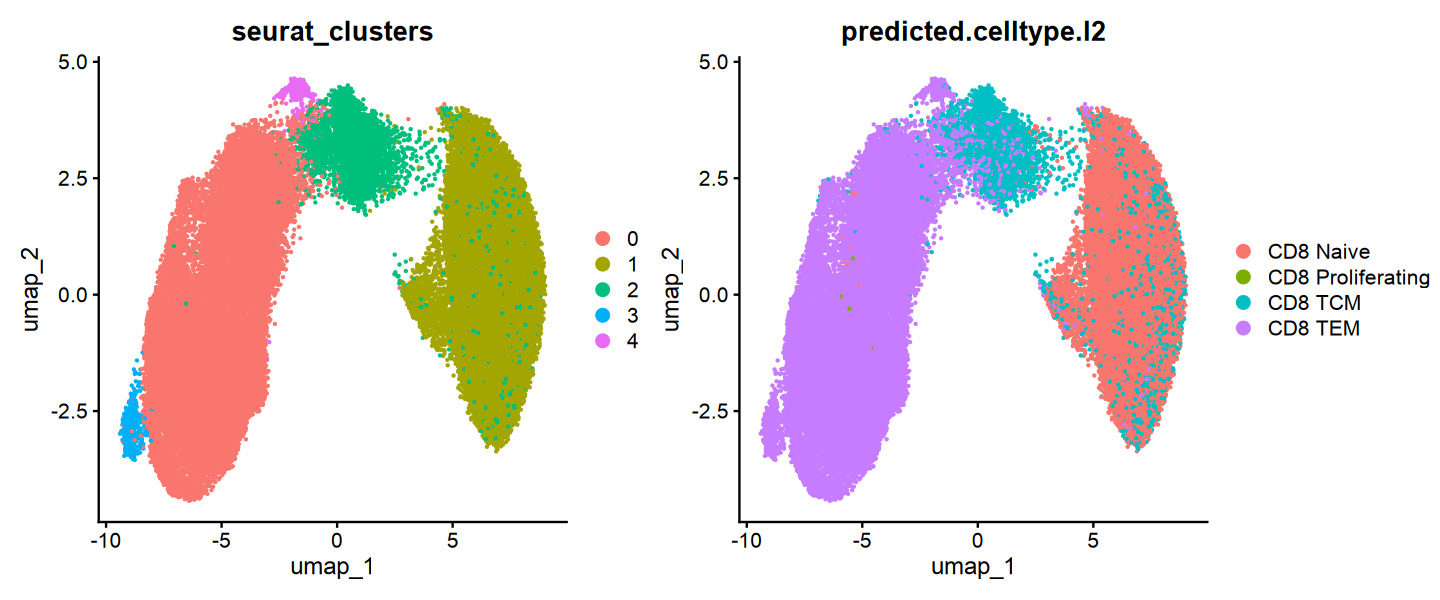

In [9]:
options(repr.plot.width=12, repr.plot.height=5)

DimPlot(obj, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

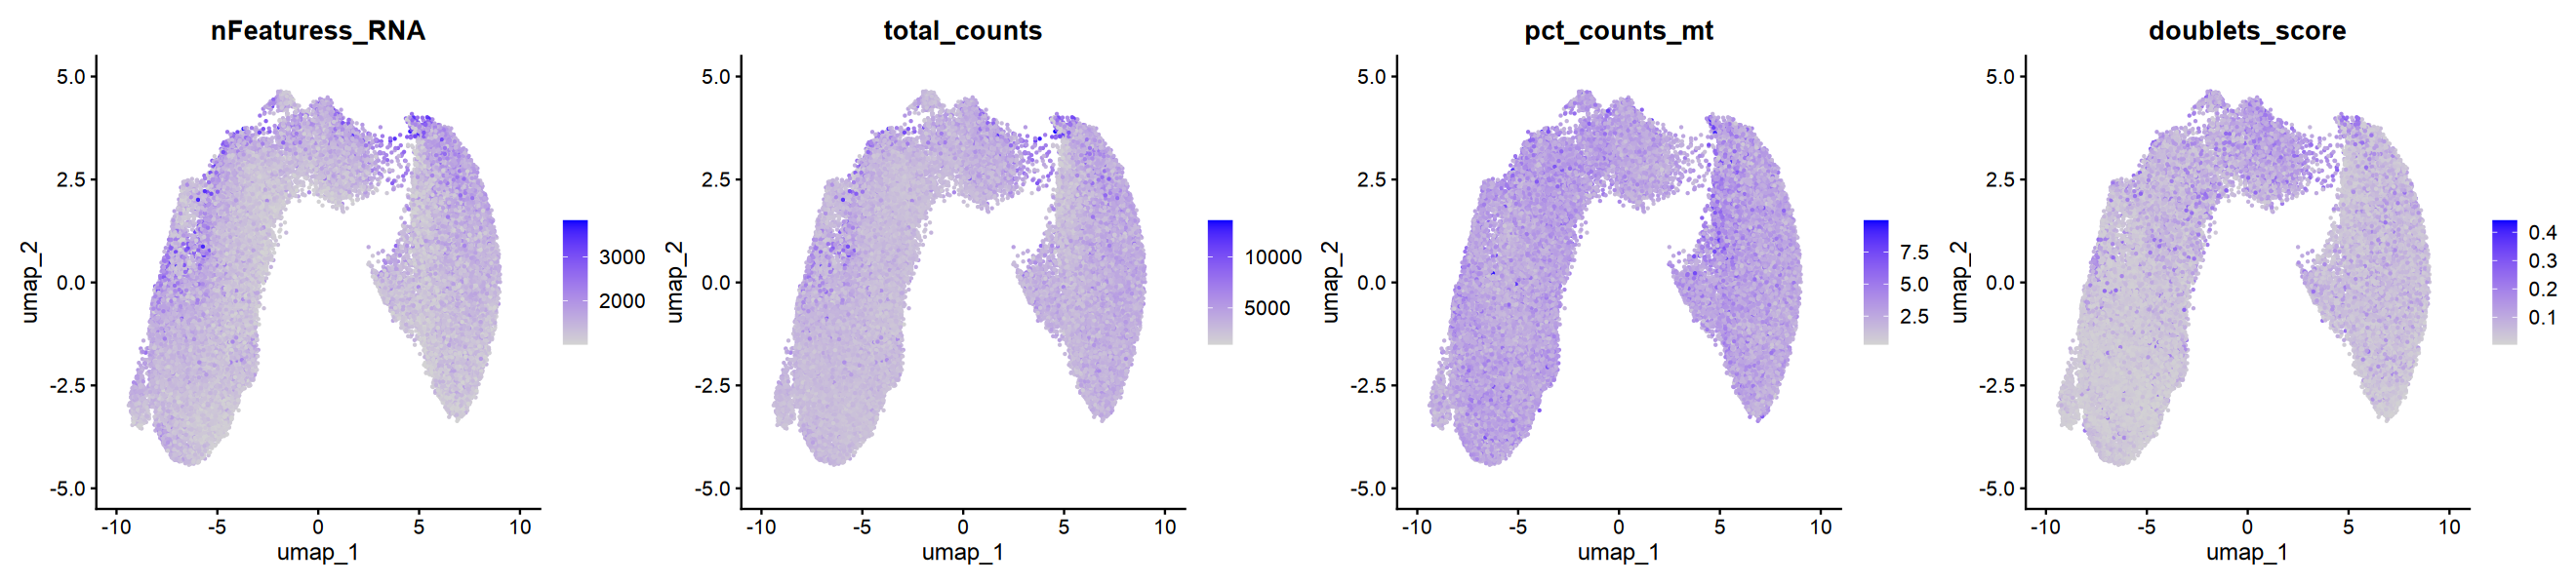

In [10]:
options(repr.plot.width=22, repr.plot.height=5)

FeaturePlot(obj, 
            features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
            reduction = 'umap', ncol=4)

Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”


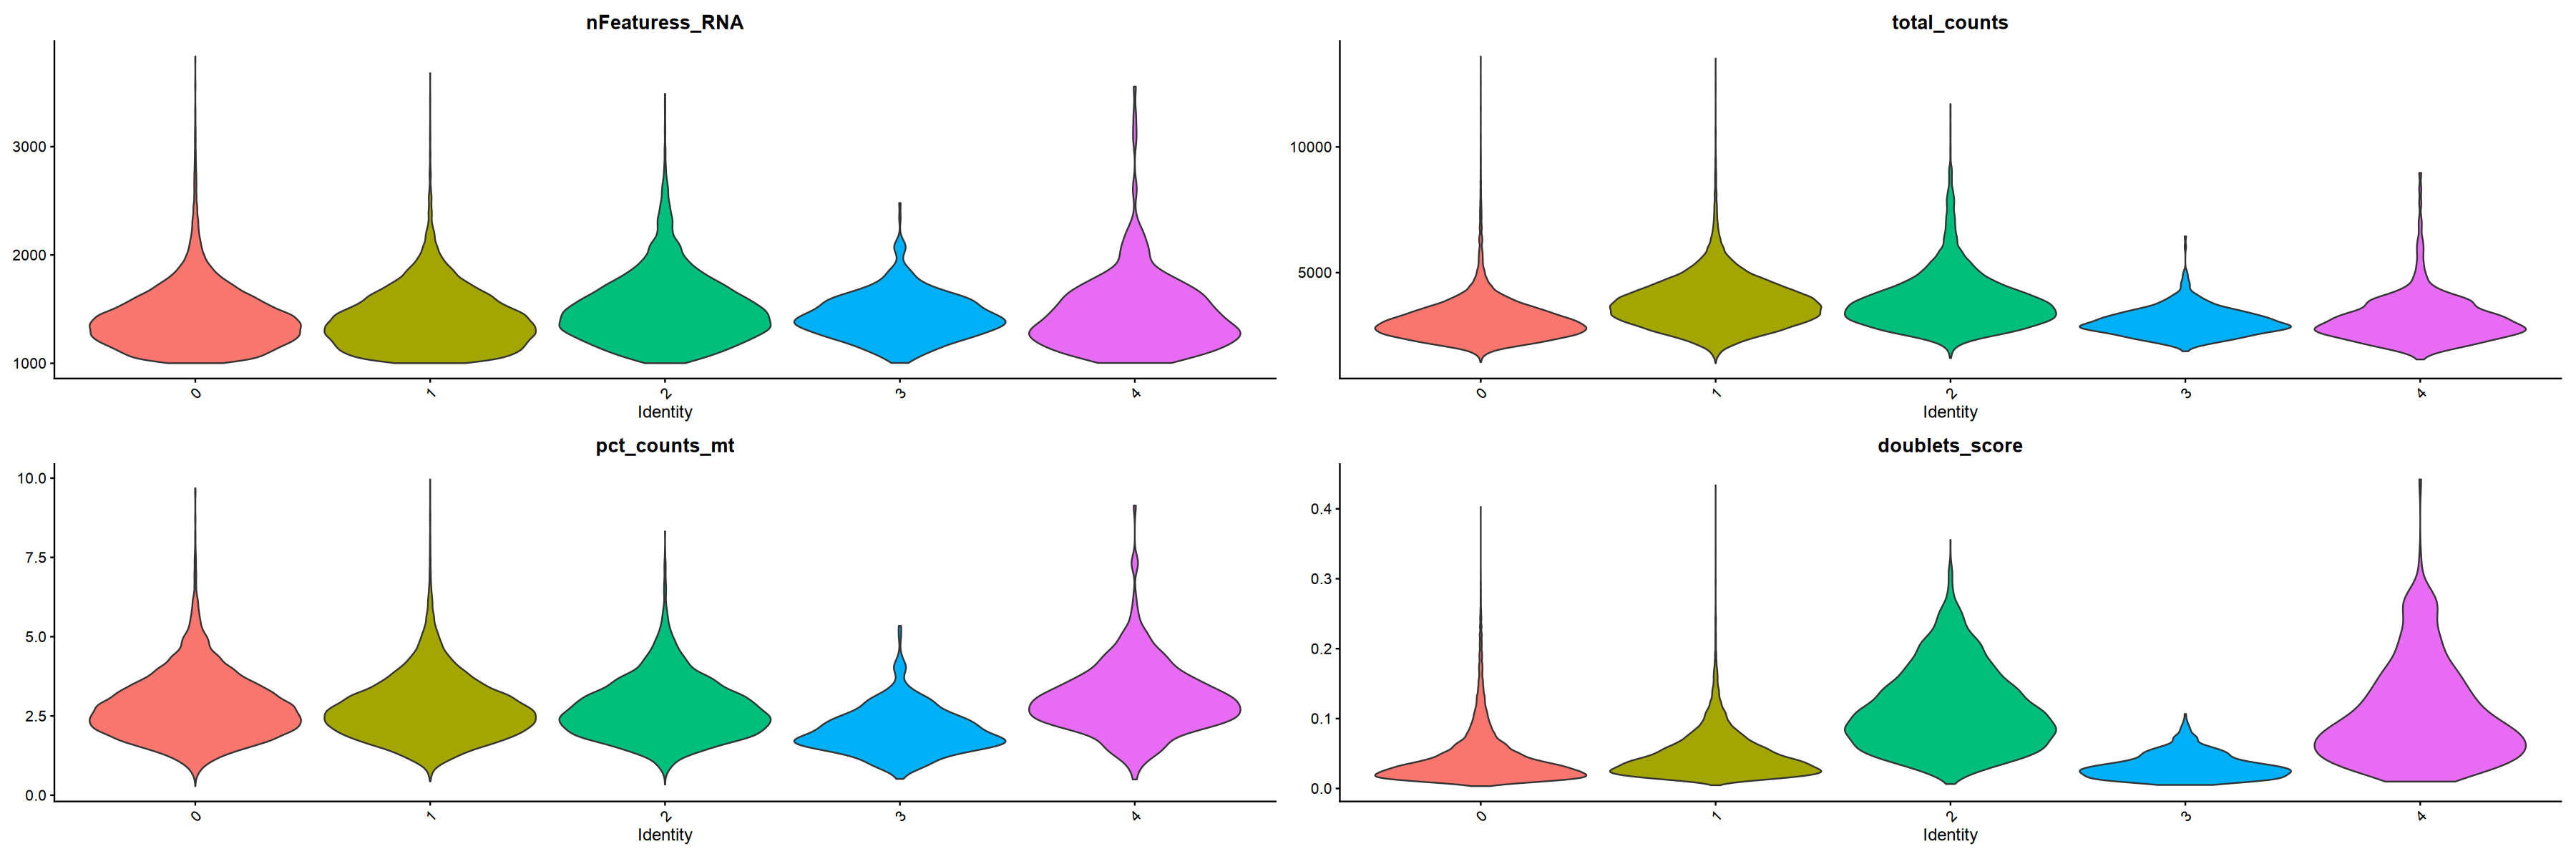

In [11]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(obj, 
        features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

The default behaviour of split.by has changed.
Separate violin plots are now plotted side-by-side.
To restore the old behaviour of a single split violin,
set split.plot = TRUE.
      
This message will be shown once per session.



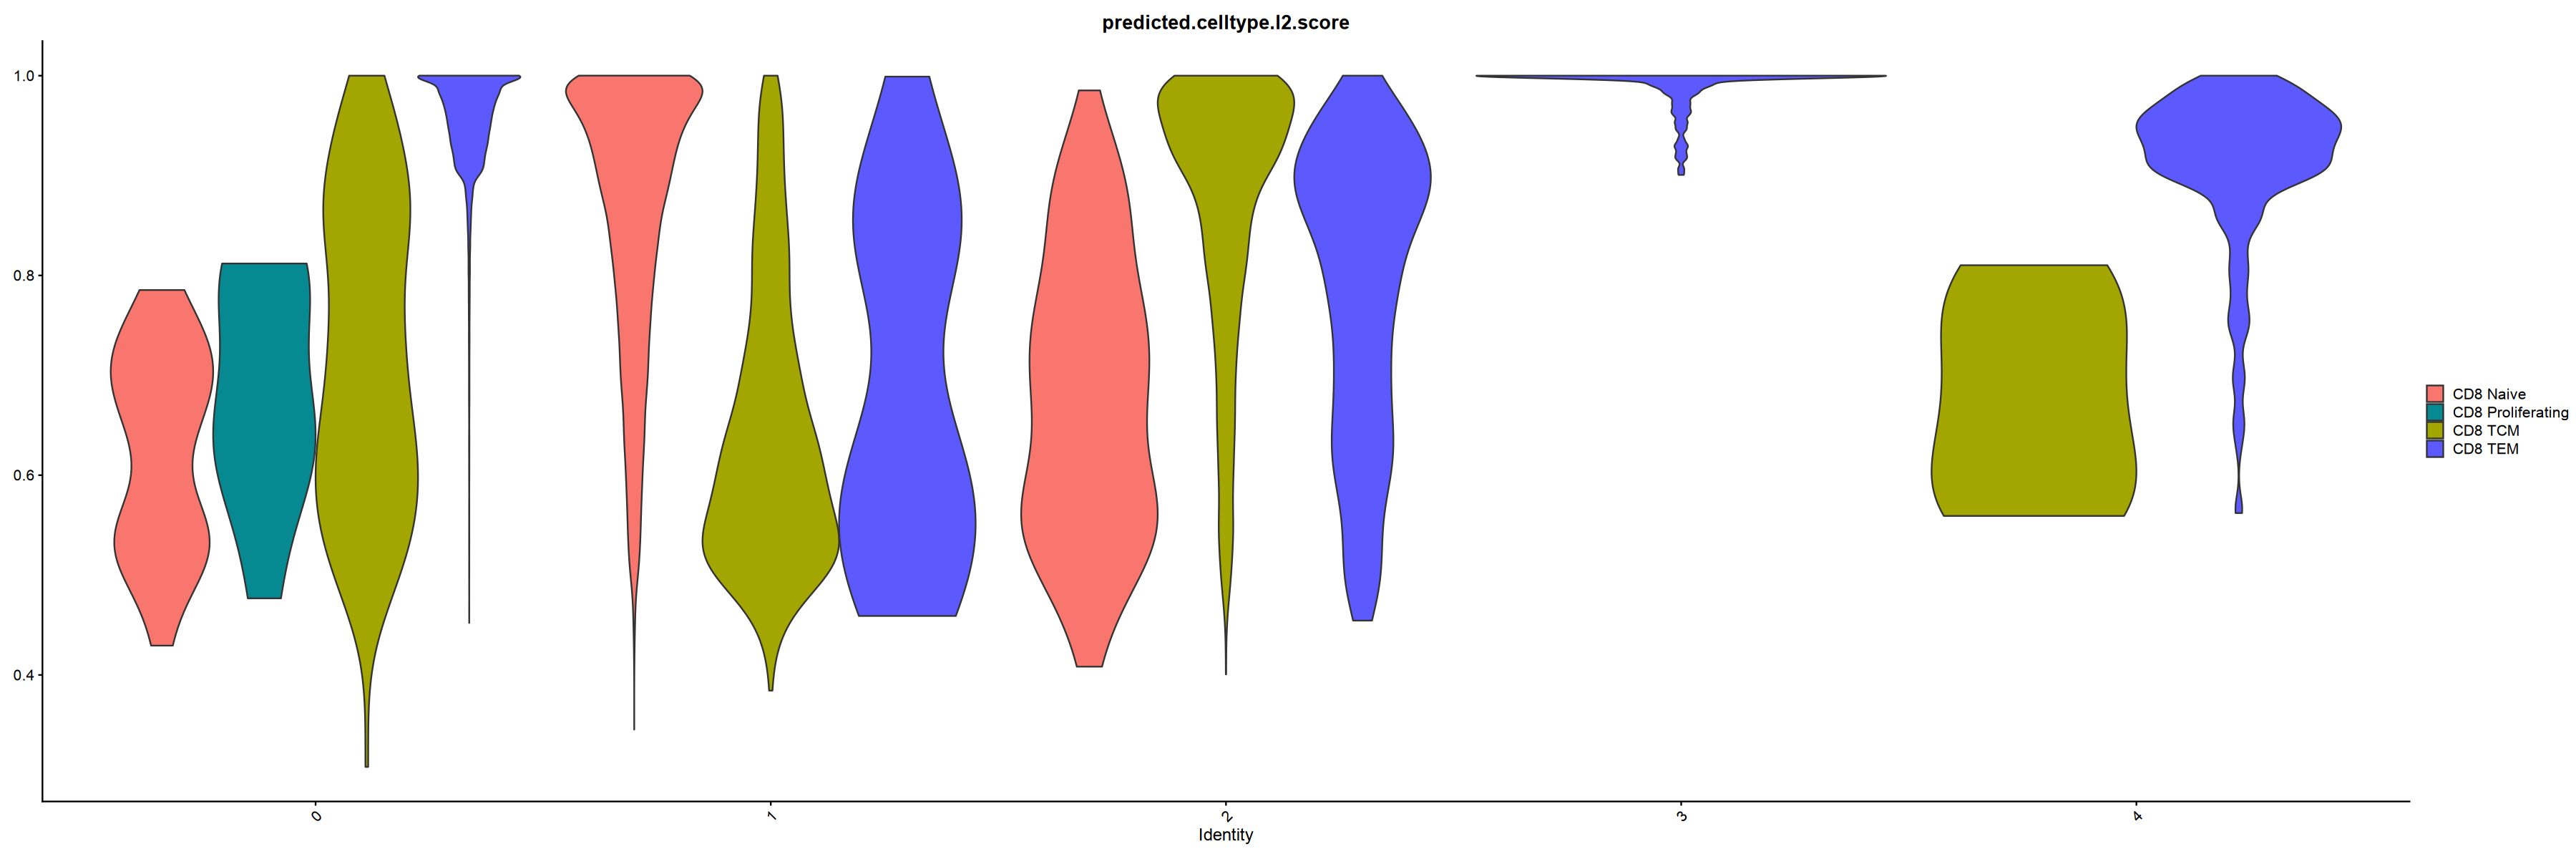

In [12]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(obj, 
        features = c('predicted.celltype.l2.score'),          
        split.by='predicted.celltype.l2', group.by='seurat_clusters', 
        ncol=1, pt.size=0)

In [34]:
# cluster 4 and 10 are likely doublets
# we filter them and redo clustering

ft = obj

ft

An object of class Seurat 
28202 features across 56566 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [35]:
ctab <- table(ft@meta.data[, c('seurat_clusters', 'predicted.celltype.l2')])
ctab_pct <- as.data.frame.matrix(prop.table(ctab, 1) * 100)

ctab_pct

,CD8 Naive,CD8 Proliferating,CD8 TCM,CD8 TEM
,<dbl>,<dbl>,<dbl>,<dbl>
0,0.1162136,0.03521623,0.4789407,99.3696295
1,93.6858072,0.00000000,6.2318527,0.0823402
2,3.0519790,0.00000000,79.7329518,17.2150691
3,0.0000000,0.00000000,0.0000000,100.0000000
4,0.0000000,0.00000000,2.3323615,97.6676385


In [36]:
max_pct <- apply(ctab_pct, 1, max)
clusters_low_purity <- as.integer(names(max_pct[max_pct < 70]) )
print(clusters_low_purity)

integer(0)


In [37]:
# for those cells which are not in clusters_low_purity, assign top predicted.celltype.l2 for that seurat_clusters
# Assume ft is your Seurat object and clusters_low_purity is already defined

# Step 1: Get cluster to top cell type mapping
ctab <- table(ft@meta.data[, c('seurat_clusters', 'predicted.celltype.l2')])
cluster_majority <- apply(ctab, 1, function(x) names(x)[which.max(x)])

# Step 2: For cells NOT in clusters_low_purity, assign top celltype
valid_clusters <- setdiff(as.integer(rownames(ctab)), clusters_low_purity)

meta_tmp <- ft@meta.data[,'seurat_clusters', drop=F]
meta_tmp$celltype_level3 <- NA  # initialize

mask <- meta_tmp$seurat_clusters %in% valid_clusters
meta_tmp$celltype_level3[mask] <- cluster_majority[as.character(meta_tmp$seurat_clusters[mask])]

anno1 = meta_tmp %>% drop_na()
dim(anno1)                       
head(anno1  )   

[1] 56566     2

,seurat_clusters,celltype_level3
,<fct>,<chr>
Pool137_10_AAACCTGAGATTACCC-1,1,CD8 Naive
Pool137_10_AAAGCAAGTGCCTTGG-1,1,CD8 Naive
Pool137_10_AAAGTAGAGATGTAAC-1,0,CD8 TEM
Pool137_10_AAAGTAGGTGTAACGG-1,0,CD8 TEM
Pool137_10_AAATGCCCACTATCTT-1,0,CD8 TEM
Pool137_10_AAATGCCTCAACGCTA-1,0,CD8 TEM


In [38]:
anno = anno1

anno = anno[Cells(ft),]

dim(anno)
head(anno)

[1] 56566     2

,seurat_clusters,celltype_level3
,<fct>,<chr>
Pool137_10_AAACCTGAGATTACCC-1,1,CD8 Naive
Pool137_10_AAAGCAAGTGCCTTGG-1,1,CD8 Naive
Pool137_10_AAAGTAGAGATGTAAC-1,0,CD8 TEM
Pool137_10_AAAGTAGGTGTAACGG-1,0,CD8 TEM
Pool137_10_AAATGCCCACTATCTT-1,0,CD8 TEM
Pool137_10_AAATGCCTCAACGCTA-1,0,CD8 TEM


In [39]:
ft = AddMetaData(ft, 
                 metadata = anno$celltype_level3, 
                 col.name = "celltype_level3")

In [40]:
table(ft@meta.data$celltype_level3)


CD8 Naive   CD8 TCM   CD8 TEM 
    23075      4194     29297 

## Save

In [41]:
map <- c(
  "CD8 Naive" = "Naive CD8T",
  "CD8 TCM" = "Central Memory CD8T",
  "CD8 TEM" = "Effector Memory CD8T")


# Map values
ft@meta.data[['celltype_level3']] <- map[ ft@meta.data[['celltype_level3']] ]

In [42]:
cell_ordered = c(
    "Naive CD8T",
    "Central Memory CD8T",
    "Effector Memory CD8T"
)

ft@meta.data[['celltype_level3']] = factor(
    ft@meta.data[['celltype_level3']],
    levels = cell_ordered
)

In [43]:
qs::qsave(ft, glue('data/03_cleandata/ft_{celltype}.qs'))

# Visualize

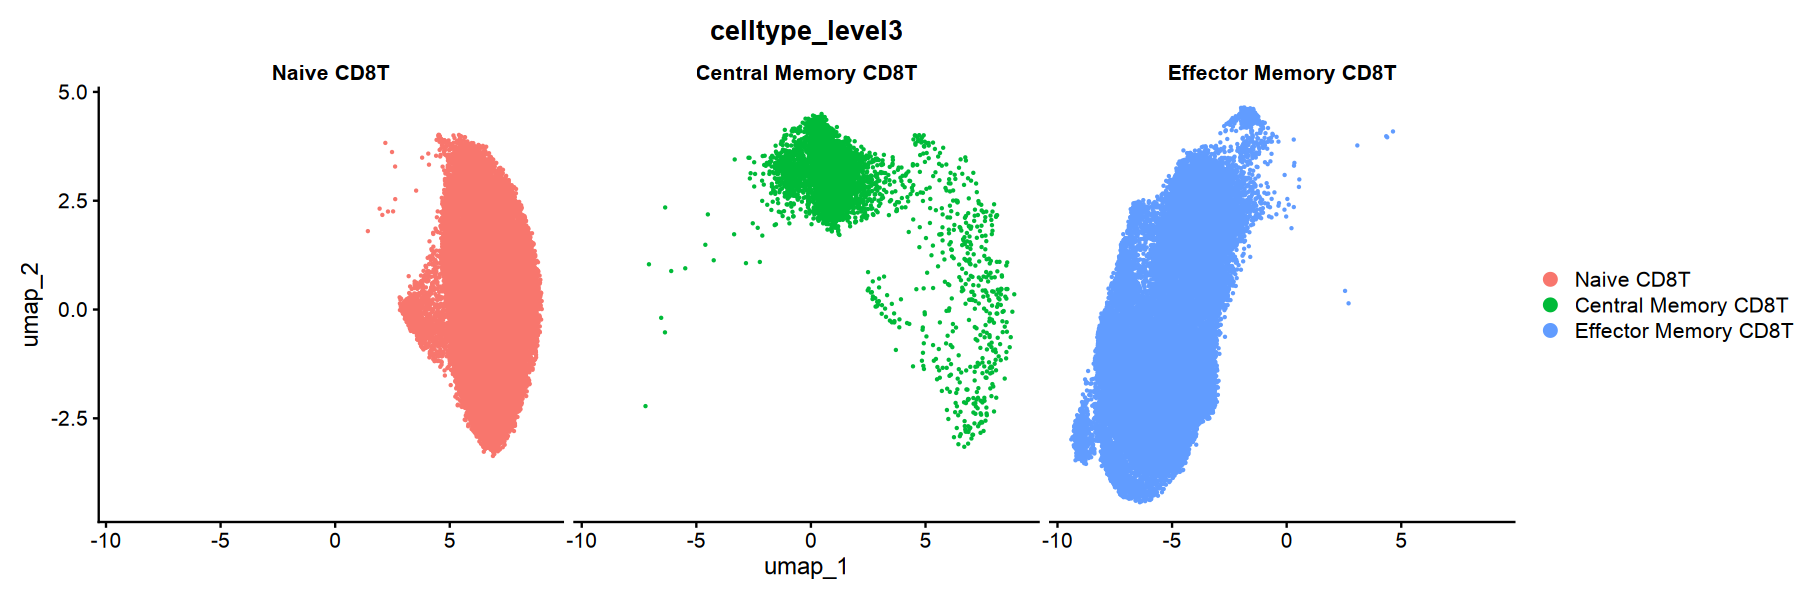

In [44]:
options(repr.plot.width=15, repr.plot.height=5)

varname = 'celltype_level3'
DimPlot(ft, reduction = "umap",  
        group.by = varname,
        split.by = varname)

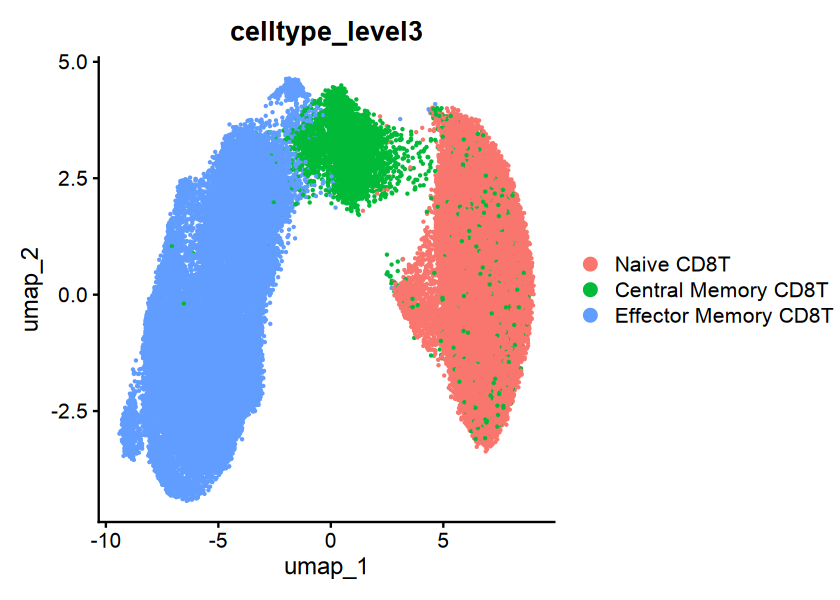

In [50]:
options(repr.plot.width=7, repr.plot.height=5)

DimPlot(ft, reduction = "umap", group.by='celltype_level3')

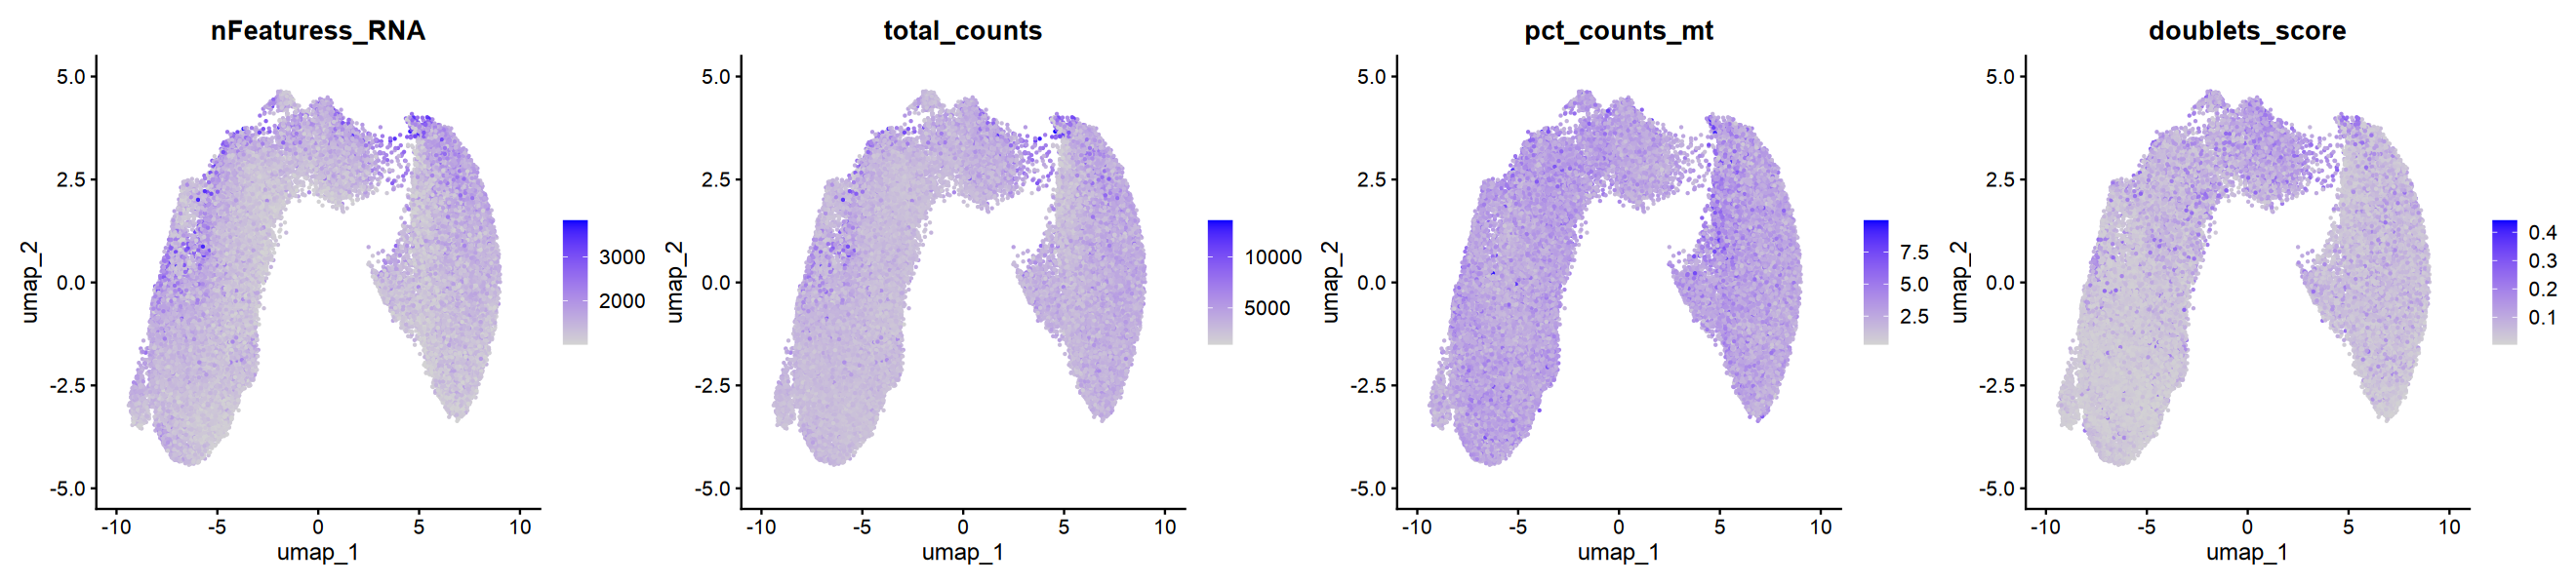

In [51]:
options(repr.plot.width=22, repr.plot.height=5)

FeaturePlot(ft, 
            features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
            reduction = 'umap', ncol=4)

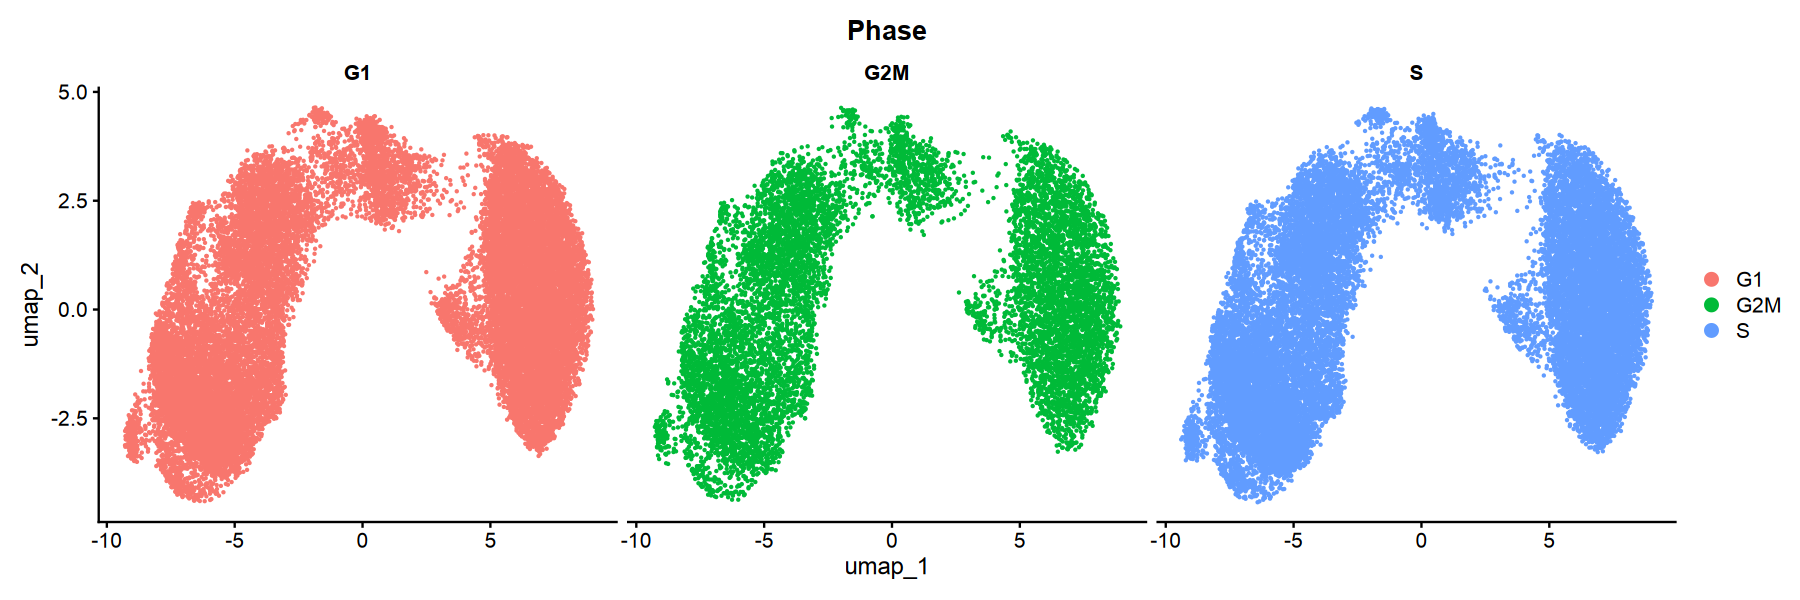

In [52]:
options(repr.plot.width=15, repr.plot.height=5)
varname = 'Phase'
DimPlot(ft, reduction = "umap",  
        group.by = varname,
        split.by = varname)

In [53]:
length(unique(ft@meta.data$dataset_name))

[1] 56

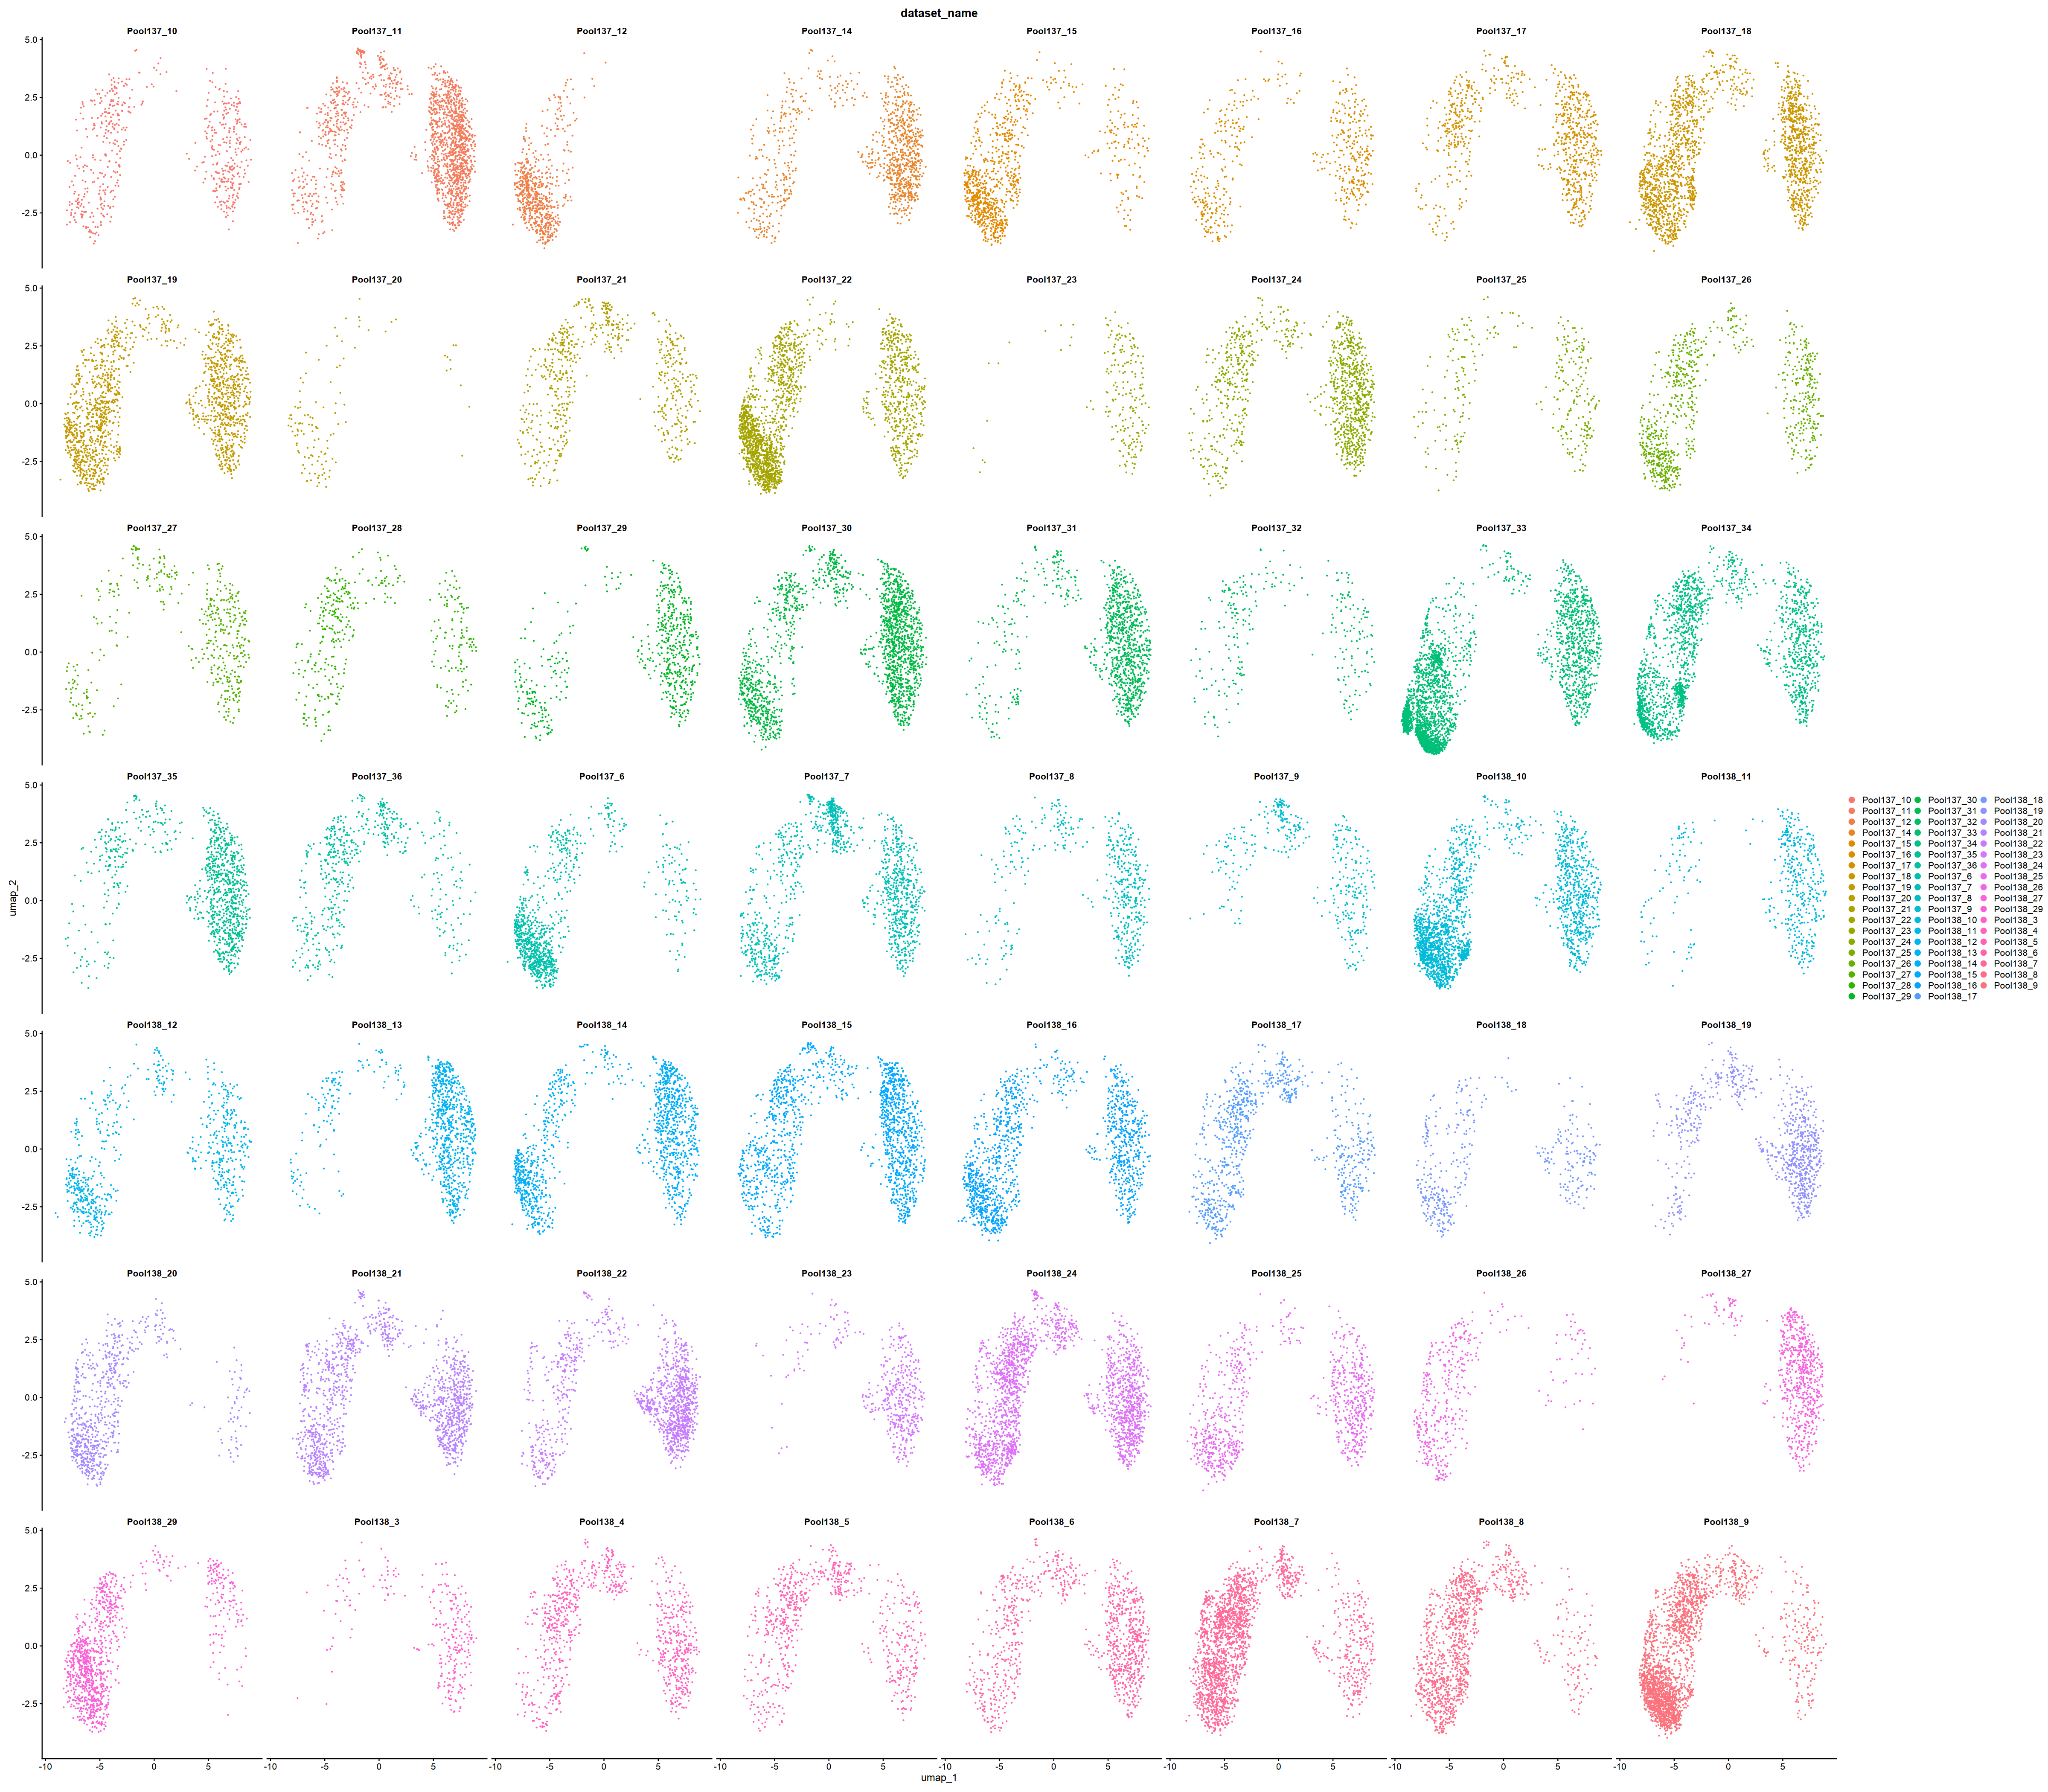

In [54]:
options(repr.plot.width=40, repr.plot.height=35)

varname = 'dataset_name'
DimPlot(ft, reduction = "umap",  
        ncol = 8,
        group.by = varname,
        split.by = varname)

# DEGs

In [55]:
Idents(ft) <- "celltype_level3"
markers <- FindAllMarkers(ft, verbose = T)
head(markers)

Calculating cluster Naive CD8T

Calculating cluster Central Memory CD8T

Calculating cluster Effector Memory CD8T



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
CCL5,0,-6.507223,0.068,0.984,0,Naive CD8T,CCL5
NKG7,0,-8.183551,0.048,0.936,0,Naive CD8T,NKG7
CST7,0,-8.802560,0.009,0.890,0,Naive CD8T,CST7
GZMA,0,-7.398647,0.017,0.822,0,Naive CD8T,GZMA
LEF1,0,3.253041,0.834,0.143,0,Naive CD8T,LEF1
CCR7,0,3.777120,0.755,0.082,0,Naive CD8T,CCR7


In [56]:
write.csv(markers, 
          glue('data/04_markergenes/{celltype}.csv'))

In [57]:
markers = read.csv(glue('data/04_markergenes/{celltype}.csv'),
                   row.names=1
                  )

cell_ordered = c(
    "Naive CD8T",
    "Central Memory CD8T",
    "Effector Memory CD8T"
)

markers$cluster = factor(
    markers$cluster,
    levels = cell_ordered
)


In [58]:
markers %>%
    group_by(cluster) %>%
    filter(p_val_adj < 0.05) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 10) %>%
    ungroup() -> top10

top10

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0,3.253041,0.834,0.143,0,Naive CD8T,LEF1
0,3.777120,0.755,0.082,0,Naive CD8T,CCR7
0,3.000406,0.769,0.148,0,Naive CD8T,BACH2
0,2.517630,0.763,0.167,0,Naive CD8T,NELL2
0,2.136919,0.810,0.223,0,Naive CD8T,SELL
0,1.699112,0.947,0.390,0,Naive CD8T,LTB
0,1.734686,0.876,0.362,0,Naive CD8T,TCF7
0,1.989135,0.833,0.330,0,Naive CD8T,NOSIP
0,3.526806,0.535,0.054,0,Naive CD8T,MAL


Warning message:
“Scaling data with a low number of groups may produce misleading results”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


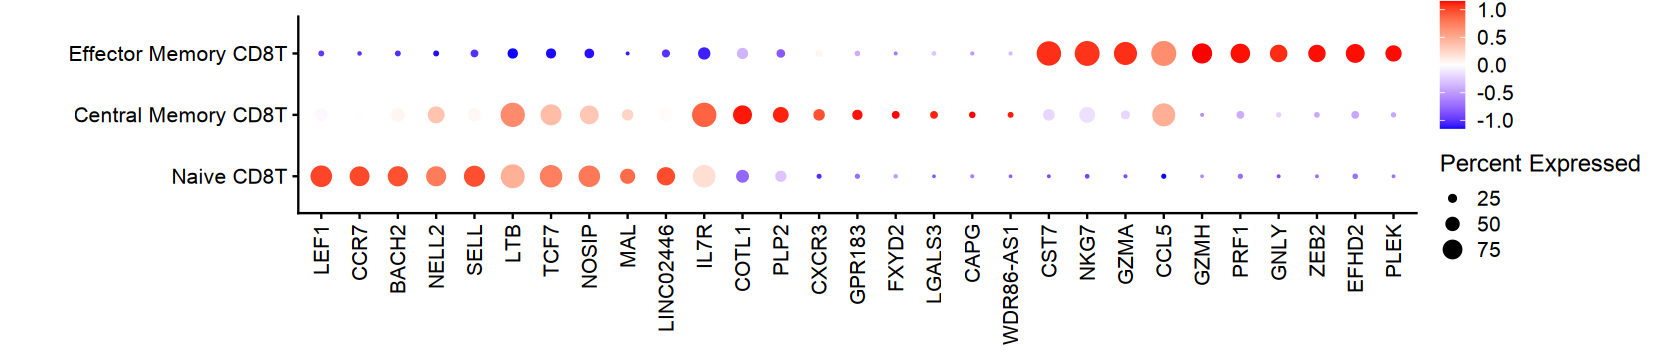

In [59]:
options(repr.plot.width=14, repr.plot.height=3)

p <- DotPlot(
  object = ft,
  features = unique(unlist(top10$gene)),
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0
  ) +
  theme(
    axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin = margin(t = 10, r = 20, b = 10, l = 50)
  )


print(p)

In [60]:
marker_azi = read.csv('data/04_markergenes/azimuth_markers.csv')
marker_azi

Level,Label,Expanded.Label,OBO.Ontology.ID,Markers
<int>,<chr>,<chr>,<chr>,<chr>
1,Mono,Monocyte,monocyte,"CTSS, FCN1, NEAT1, LYZ, PSAP, S100A9, AIF1, MNDA, SERPINA1, TYROBP"
1,CD4 T,CD4+ T cell,"CD4-positive, alpha-beta T cell","IL7R, MAL, LTB, CD4, LDHB, TPT1, TRAC, TMSB10, CD3D, CD3G"
1,CD8 T,CD8+ T cell,"CD8-positive, alpha-beta T cell","CD8B, CD8A, CD3D, TMSB10, HCST, CD3G, LINC02446, CTSW, CD3E, TRAC"
1,NK,natural killer cell,natural killer cell,"NKG7, KLRD1, TYROBP, GNLY, FCER1G, PRF1, CD247, KLRF1, CST7, GZMB"
1,B,B cell,mature B cell,"CD79A, RALGPS2, CD79B, MS4A1, BANK1, CD74, TNFRSF13C, HLA-DQA1, IGHM, MEF2C"
1,other T,other T cell,mature T cell,"CD3D, TRDC, GZMK, KLRB1, NKG7, TRGC2, CST7, LYAR, KLRG1, GZMA"
1,DC,dendritic cell,dendritic cell,"CD74, HLA-DPA1, HLA-DPB1, HLA-DQA1, CCDC88A, HLA-DRA, HLA-DMA, CST3, HLA-DQB1, HLA-DRB1"
2,B intermediate,Intermediate B cell,mature B cell,"MS4A1, TNFRSF13B, IGHM, IGHD, AIM2, CD79A, LINC01857, RALGPS2, BANK1, CD79B"
2,B memory,Memory B cell,memory B cell,"MS4A1, COCH, AIM2, BANK1, SSPN, CD79A, TEX9, RALGPS2, TNFRSF13C, LINC01781"


In [61]:
names_sel <- c(
  "CD8 Naive", 
  "CD8 TCM", 
  "CD8 TEM"
    )  # <- your cell types of interest

# Filter marker_azi for the selected labels
marker_df <- marker_azi %>% 
filter(Level == 2) %>%
filter(Label %in% names_sel)

# Split the comma-separated Markers into list elements, assign names
markers <- setNames(
  strsplit(marker_df$Markers, ",\\s*"),   # split each marker by comma + space
  marker_df$Label
)

markers

$`CD8 Naive`
 [1] "CD8B"      "S100B"     "CCR7"      "RGS10"     "NOSIP"     "LINC02446"
 [7] "LEF1"      "CRTAM"     "CD8A"      "OXNAD1"   

$`CD8 TCM`
 [1] "CD8B"      "ANXA1"     "CD8A"      "KRT1"      "LINC02446" "YBX3"     
 [7] "IL7R"      "TRAC"      "NELL2"     "LDHB"     

$`CD8 TEM`
 [1] "CCL5"  "GZMH"  "CD8A"  "TRAC"  "KLRD1" "NKG7"  "GZMK"  "CST7"  "CD8B" 
[10] "TRGC2"

In [62]:
# Set your desired cell type order:
type_order <- names_sel

# Unlist markers in that order, dropping duplicates but preserving order:
features_to_plot <- unlist(markers[type_order], use.names = FALSE)
features_to_plot <- features_to_plot[!duplicated(features_to_plot)]  # Remove duplicates, keep order

# Optionally, keep only genes present in your Seurat object:
features_to_plot <- features_to_plot[features_to_plot %in% rownames(ft)]
features_to_plot

[1] "CD8B"      "S100B"     "CCR7"      "RGS10"     "NOSIP"     "LINC02446"
 [7] "LEF1"      "CRTAM"     "CD8A"      "OXNAD1"    "ANXA1"     "KRT1"     
[13] "YBX3"      "IL7R"      "TRAC"      "NELL2"     "LDHB"      "CCL5"     
[19] "GZMH"      "KLRD1"     "NKG7"      "GZMK"      "CST7"      "TRGC2"

Warning message:
“Scaling data with a low number of groups may produce misleading results”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


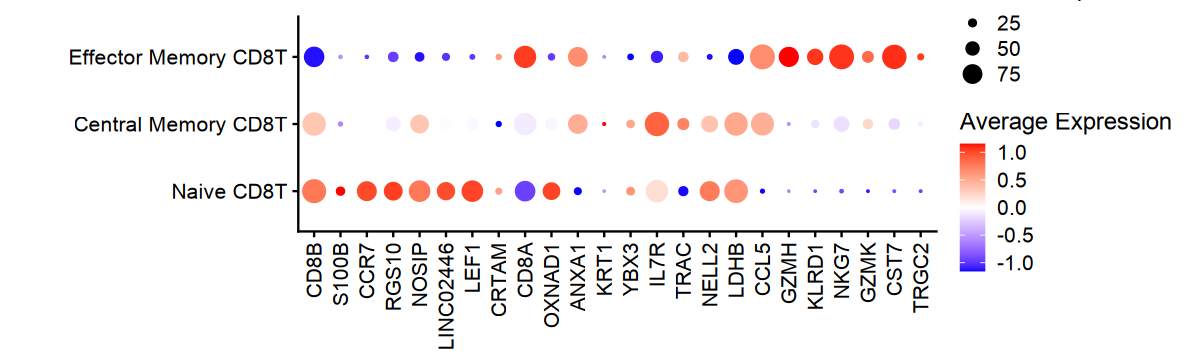

In [63]:
options(repr.plot.width=10, repr.plot.height=3)

p <- DotPlot(
  object = ft,
  features = features_to_plot,
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0
  ) +
  theme(
    axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin = margin(t = 10, r = 20, b = 10, l = 50)
  )

print(p)

# MS4A1''TNFRSF13B''IGHM''IGHD''AIM2''CD79A''LINC01857''RALGPS2''BANK1''CD79B'

Warning message in DoHeatmap(subset(ft, downsample = 100), features = features_to_plot, :
“The following features were omitted as they were not found in the scale.data slot for the RNA assay: KRT1, CD8A, CD8B”


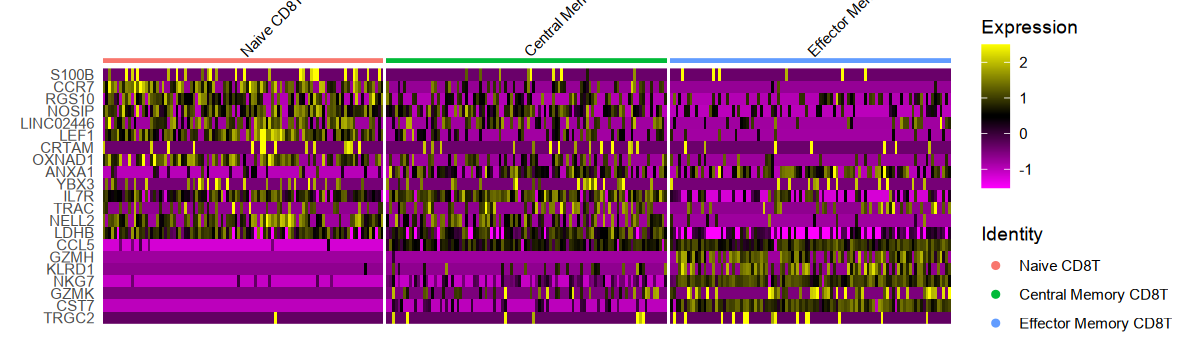

In [64]:
Idents(ft) =  "celltype_level3"

DoHeatmap(subset(ft, downsample = 100), 
          features = features_to_plot, size = 3)